# JPEG image analysis

In this notebook, we will load either the subset or full data set. 

We will check if all JPEG files are readable and linked corrected; inspect the dimensions, aspect ratios and file sizes; explore the variance in the colour, brightness, contrast and sharpness; check for anomalous, duplicate, or artefact images. 

We will also explore the difference in the properties between the benign and malignant images.

Moreover, among the train, validation and test sets, we will analyse whether there are technical differences among these.


We will also extract any numerical image features, or embeddings if possible.

## Subset exploration

In [13]:
# import relevant libraries
from pathlib import Path
from PIL import Image
import pandas as pd

DATASET_SCOPE = "full"

PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"

if DATASET_SCOPE == 'subset':
    index_path = DATA_DIR / "derived"/ 'splits'/'subset_split_index.csv'
else:
    index_path = DATA_DIR / "derived"/ 'splits'/'full_train_split_index.csv'


image_index = pd.read_csv(index_path)

print("Images to audit: ", len(image_index))
# check the image index
image_index[['image_name','jpeg_path']].head()


Images to audit:  33126


,image_name,jpeg_path
0,ISIC_2637011,data/jpeg/train/ISIC_2637011.jpg
1,ISIC_0015719,data/jpeg/train/ISIC_0015719.jpg
2,ISIC_0052212,data/jpeg/train/ISIC_0052212.jpg
3,ISIC_0068279,data/jpeg/train/ISIC_0068279.jpg
4,ISIC_0074268,data/jpeg/train/ISIC_0074268.jpg


We need to check through each jpeg image ensuring that:
1. A path was supplied
2. Whether the file exists
3. Can pillow open and fully decode it?
4. We inspect its original format, colour mode and dimensions
5. No errors?

In [14]:
# confirm if the first path is workable
first_path = Path(image_index.loc[0,'jpeg_path'])

if not first_path.is_absolute():
    first_path = PROJECT_ROOT / first_path

print(first_path)
print("Exists: ", first_path.is_file())

c:\Users\madis\Documents\ADS2002-Melanoma\data\jpeg\train\ISIC_2637011.jpg
Exists:  True


In [15]:
def check_jpeg(image_name, jpeg_path):
    result = {
        'image_name': image_name,
        'jpeg_path': jpeg_path,
        'path_exists': False,
        'readable': False,
        'image_format': None,
        'colour_mode': None,
        'width': None,
        'height': None,
        'file_size_kb': None,
        'error_type': None,
        'error_message': None

    }

    if pd.isna(jpeg_path):
        result['error_type'] = "missing_path"
        result['error_message'] = 'No JPEG path was supplied'

        return result

    path = Path(jpeg_path)

    if not path.is_absolute():
        path = PROJECT_ROOT / path


    if not path.is_file():
        result['error_type'] = "file_not_found"
        result['error_message'] = "JPEG file does not exist"


        return result

    result['path_exists'] = True
    result['file_size_kb'] = path.stat().st_size / 1024


    try:
        with Image.open(path) as image:
            image.load()

            result["readable"] = True
            result["image_format"] = image.format
            result["colour_mode"] = image.mode
            result["width"], result["height"] = image.size


    except Exception as error:
        result['error_type'] = type(error).__name__
        result['error_message'] = str(error)

    return result

In [16]:
from tqdm.auto import tqdm

In [17]:
check_record = []


for row in tqdm(
    image_index.itertuples(index=False),
    total=len(image_index),
    desc=f'Checking {DATASET_SCOPE} JPEGs'):
    check_record.append(
        check_jpeg(image_name=row.image_name,
                   jpeg_path=row.jpeg_path)
    )

jpeg_check = pd.DataFrame(check_record)

Checking full JPEGs:   0%|          | 0/33126 [00:00<?, ?it/s]

In [18]:
# merge information together


jpeg_check = image_index[['image_name', 'patient_id', 'target', 'model_split']].merge(
    jpeg_check, on='image_name',how='left',validate='one_to_one'
)


check_summary = pd.Series({
    'indexed_images': len(jpeg_check),
    'existing_files': jpeg_check['path_exists'].sum(),
    'readable_files': jpeg_check['readable'].sum(),
    'missing_files': (~jpeg_check['path_exists']).sum(),
    'unreadable_files': (jpeg_check['path_exists'] & ~jpeg_check['readable']).sum()})

check_summary

indexed_images      33126
existing_files      33126
readable_files      33126
missing_files           0
unreadable_files        0
dtype: int64

In [19]:
# no problems, proceed to inspecting the formats and colour modes


jpeg_check['image_format'].value_counts(dropna=False)


image_format
JPEG    33126
Name: count, dtype: int64

In [20]:
jpeg_check['colour_mode'].value_counts(dropna=False)


colour_mode
RGB    33126
Name: count, dtype: int64

In [21]:
# formats and colour modes are consistent


OUTPUT_DIR = DATA_DIR / "derived" / "image_statistics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_path = OUTPUT_DIR / f"{DATASET_SCOPE}_jpeg_integrity.csv"

jpeg_check.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: c:\Users\madis\Documents\ADS2002-Melanoma\data\derived\image_statistics\full_jpeg_integrity.csv


## Derive technical features

In [49]:
import numpy as np

jpeg_statistics = jpeg_check.copy()

jpeg_statistics['aspect_ratio'] = (jpeg_statistics['width'] / jpeg_statistics['height'])

jpeg_statistics['megapixels'] = (jpeg_statistics['width'] * jpeg_statistics['height'])/1_000_000

jpeg_statistics['orientation'] = np.select(
    [
        jpeg_statistics['width'] > jpeg_statistics['height'],
        jpeg_statistics['width'] < jpeg_statistics['height']
    ],
    ['landscape','portrait'],
    default='square'
)



In [50]:
# summary


technical_features = ['width',
                      'height',
                      'aspect_ratio',
                      'megapixels',
                      'file_size_kb']


jpeg_statistics[technical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
width,33126.0,4039.630381,2109.145590,640.000000,1872.000000,5184.000000,6000.000000,6000.000000
height,33126.0,2678.758256,1437.617626,480.000000,1053.000000,3456.000000,4000.000000,6000.000000
aspect_ratio,33126.0,1.527957,0.155173,0.664179,1.500000,1.500000,1.500000,1.781473
megapixels,33126.0,13.835896,10.306168,0.307200,1.971216,17.915904,24.000000,24.000000
file_size_kb,33126.0,759.508221,589.845979,15.425781,142.493652,819.487305,1222.022461,3406.907227


#### Comments on technical features


Full dataset:
- ranges?
- outliers?
- small files?
- unusual resolutions?
- missing values?




Subset:
- ranges?
- outliers?
- small files?
- unusual resolutions?
- missing values?



In [51]:
# format and dimensions

jpeg_statistics['colour_mode'].value_counts(dropna=False)

colour_mode
RGB    33126
Name: count, dtype: int64

In [52]:
jpeg_statistics['orientation'].value_counts()

orientation
landscape    32935
square         150
portrait        41
Name: count, dtype: int64

### Examine key distributions

In [53]:
# !pip install -q seaborn

Text(0.5, 1.0, 'Aspect-ratio distribution FTDS')

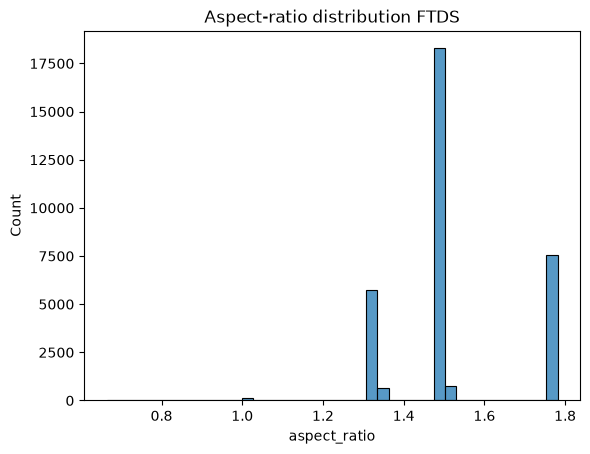

In [54]:
import seaborn as sns

import matplotlib.pyplot as plt


sns.histplot(
    data=jpeg_statistics,
    x='aspect_ratio',
    bins=40
)

plt.title("Aspect-ratio distribution FTDS")

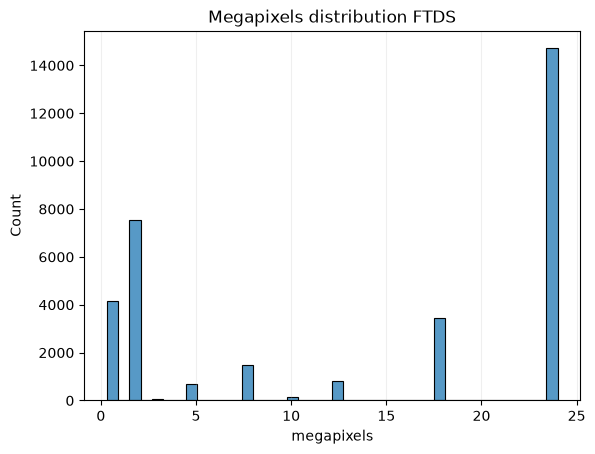

In [ ]:
sns.histplot(
    data=jpeg_statistics,
    x='megapixels',
    bins=40
)

plt.title("Megapixels distribution FTDS")


Text(0.5, 1.0, 'File size (kb) distribution FTDS')

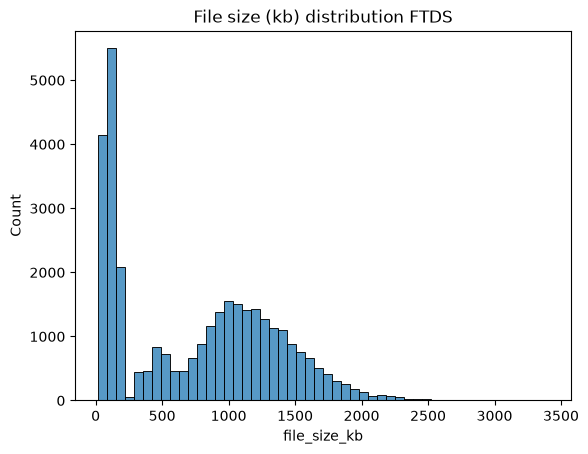

In [77]:
sns.histplot(
    data=jpeg_statistics,
    x='file_size_kb',
    bins=50
)

plt.title("File size (kb) distribution FTDS")

In [78]:
jpeg_statistics.columns

Index(['image_name', 'patient_id', 'target', 'model_split', 'jpeg_path',
       'path_exists', 'readable', 'image_format', 'colour_mode', 'width',
       'height', 'file_size_kb', 'error_type', 'error_message', 'aspect_ratio',
       'megapixels', 'orientation', 'resolution'],
      dtype='str')

In [ ]:
sns.histplot(
    data=jpeg_statistics,
    x='file_size_kb',
    bins=50
)

plt.title("File size (kb) distribution FTDS")

In [62]:
resolution_counts = (
    jpeg_statistics
    .groupby(["width", "height"])
    .size()
    .reset_index(name="count")
)

resolution_counts["resolution"] = (
    resolution_counts["width"].astype(int).astype(str)
    + " × "
    + resolution_counts["height"].astype(int).astype(str)
)

resolution_counts["megapixels"] = (
    resolution_counts["width"]
    * resolution_counts["height"]
    / 1_000_000
)

resolution_counts = resolution_counts.sort_values("megapixels")

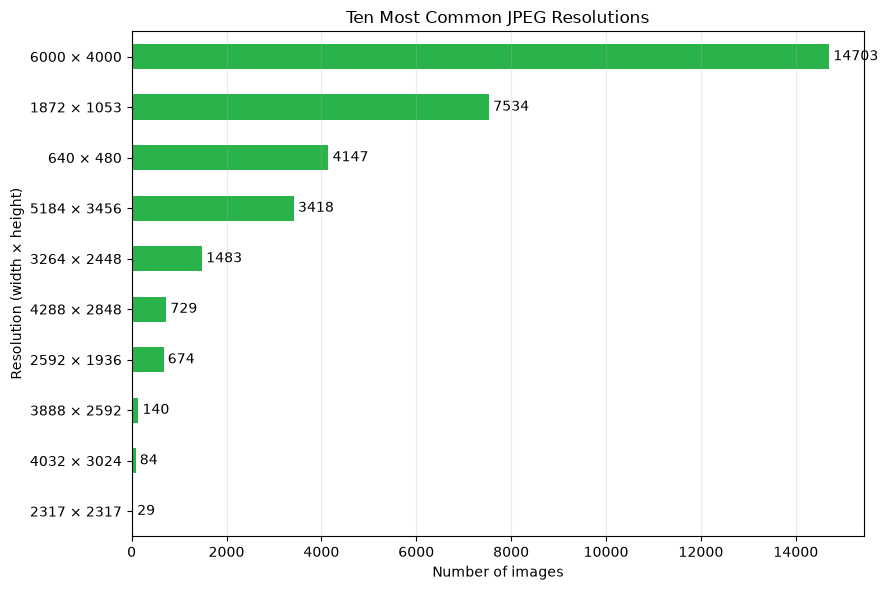

In [72]:
jpeg_statistics["resolution"] = (
    jpeg_statistics["width"].astype(int).astype(str)
    + " × "
    + jpeg_statistics["height"].astype(int).astype(str)
)

top_resolutions = (
    jpeg_statistics["resolution"]
    .value_counts()
    .head(10)
    .sort_values()
)


fig, ax = plt.subplots(figsize=(9, 6))

top_resolutions.plot(
    kind="barh",
    ax=ax,
    color="#2ab34a"
)

ax.set_title("Ten Most Common JPEG Resolutions")
ax.set_xlabel("Number of images")
ax.set_ylabel("Resolution (width × height)")
ax.bar_label(ax.containers[0], padding=3)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()




In [79]:
jpeg_statistics.groupby("model_split")[
    technical_features
].median()

,width,height,aspect_ratio,megapixels,file_size_kb
model_split,,,,,
test,5184.0,3456.0,1.5,17.915904,906.703125
train,5184.0,3456.0,1.5,17.915904,817.670898
validation,5184.0,3456.0,1.5,17.915904,695.828125


In [ ]:
# extreme images - 10 smallest file size
jpeg_statistics.nsmallest(10, 'file_size_kb')[['image_name','file_size_kb','width','height']]


,image_name,file_size_kb,width,height
29518,ISIC_8924942,15.425781,640,480
30511,ISIC_9218984,16.016602,640,480
4694,ISIC_1507583,16.074219,640,480
10675,ISIC_3296066,16.169922,640,480
33075,ISIC_9985776,16.234375,640,480
22182,ISIC_6717114,16.612305,640,480
15897,ISIC_4863708,16.624023,640,480
26684,ISIC_8087743,16.716797,640,480
633,ISIC_0293967,16.938477,640,480
5563,ISIC_1763577,17.000000,640,480


In [85]:
jpeg_statistics.nlargest(10, 'file_size_kb')[['image_name','file_size_kb','width','height']]


,image_name,file_size_kb,width,height
26924,ISIC_8158542,3406.907227,6000,4000
4774,ISIC_1534609,3331.684570,6000,4000
23224,ISIC_7059744,3192.092773,6000,4000
30526,ISIC_9223743,3108.744141,6000,4000
31589,ISIC_9548034,2988.560547,6000,4000
2872,ISIC_0956818,2953.389648,6000,4000
25535,ISIC_7751233,2948.998047,6000,4000
901,ISIC_0374231,2922.321289,6000,4000
26987,ISIC_8175524,2920.333008,6000,4000
14580,ISIC_4468474,2887.938477,6000,4000


In [86]:
jpeg_statistics.nlargest(10, 'aspect_ratio')[['image_name','file_size_kb','width','height']]


,image_name,file_size_kb,width,height
4131,ISIC_1348254,1203.344727,6000,3368
2,ISIC_0052212,135.268555,1872,1053
3,ISIC_0068279,210.698242,1872,1053
12,ISIC_0076995,137.041992,1872,1053
26,ISIC_0084086,134.033203,1872,1053
27,ISIC_0084270,129.601562,1872,1053
28,ISIC_0084395,142.699219,1872,1053
32,ISIC_0086349,141.093750,1872,1053
41,ISIC_0089569,130.557617,1872,1053
42,ISIC_0089738,131.862305,1872,1053


In [87]:
jpeg_statistics.nsmallest(10, 'aspect_ratio')[['image_name','file_size_kb','width','height']]


,image_name,file_size_kb,width,height
2473,ISIC_0839367,615.500977,2848,4288
4067,ISIC_1328868,634.727539,2848,4288
5092,ISIC_1630301,460.611328,2848,4288
6657,ISIC_2087446,580.306641,2848,4288
6714,ISIC_2105563,491.516602,2848,4288
7966,ISIC_2482667,462.669922,2848,4288
7999,ISIC_2492245,492.809570,2848,4288
8810,ISIC_2741962,315.009766,2848,4288
10211,ISIC_3162245,339.086914,2848,4288
11294,ISIC_3480565,768.664062,2848,4288


In [73]:
statistics_path = (
    DATA_DIR
    / "derived"
    / "image_statistics"
    / f"{DATASET_SCOPE}_jpeg_statistics.csv"
)

jpeg_statistics.to_csv(statistics_path, index=False)

## Visual EDA



In [88]:
training_images = jpeg_statistics[
    jpeg_statistics["model_split"] == "train"
]